<center><h1>Tiwari_Manas_HW3</h1></center>
<br>
<br>

Name: Manas Tiwari

Github Username: mt431

USC ID: 5446032746

## 1. Time Series Classification Part 1: Feature Creation/Extraction

### (a) Download Data

Package imports

In [8]:
import zipfile
from io import StringIO

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd


Get the AReM Data Set

In [9]:
columns = ["time", "avg_rss12", "var_rss12", "avg_rss13",
           "var_rss13", "avg_rss23", "var_rss23"]
recordings = []

with zipfile.ZipFile("../data/AReM.zip") as archive:
    files = [name for name in archive.namelist() if name.endswith(".csv")]
    files.sort(key=lambda name: (name.split("/")[0],
                                int(name.split("dataset")[1].split(".")[0])))

    for filename in files:
        lines = archive.read(filename).decode("utf-8").splitlines()
        # Needed to handle empty trailing fields
        measurements = "\n".join(line.strip().rstrip(",") for line in lines[5:])
        data = pd.read_csv(StringIO(measurements), sep=r"[,\s]+",
                           engine="python", header=None, names=columns)
        assert data.shape[1] == 7
        assert not data.isna().any().any(), filename
        assert all(pd.api.types.is_numeric_dtype(data[col]) for col in columns)
        assert data["time"].is_unique, filename
        assert data["time"].is_monotonic_increasing, filename
        expected_rows = 479 if filename == "sitting/dataset8.csv" else 480
        assert len(data) == expected_rows, filename
        expected_times = pd.Index(range(0, 120000, 250))
        missing_times = expected_times.difference(data["time"])
        assert data["time"].isin(expected_times).all(), filename
        assert list(missing_times) == ([13500] if expected_rows == 479 else []), filename

        recordings.append({"activity": filename.split("/")[0],
                           "filename": filename.split("/")[-1], "data": data})

assert len(recordings) == 88
assert len({recording["activity"] for recording in recordings}) == 7
summary = {
    "recordings": len(recordings),
    "activities": len({recording["activity"] for recording in recordings}),
    "sensor_series_per_recording": len(columns) - 1,
    "recordings_with_480_rows": sum(len(recording["data"]) == 480 for recording in recordings),
    "recordings_with_479_rows": sum(len(recording["data"]) == 479 for recording in recordings),
    "missing_entries": sum(recording["data"].isna().sum().sum() for recording in recordings)
}
summary


{'recordings': 88,
 'activities': 7,
 'sensor_series_per_recording': 6,
 'recordings_with_480_rows': 87,
 'recordings_with_479_rows': 1,
 'missing_entries': np.int64(0)}

Data loading notes:

- Whitespace-separated measurements in dataset4.csv and trailing commas in dataset9.csv & dataset14.csv needed to be handled explicitly while loading
- dataset8.csv is missing the observation at timestamp 13500. All other recordings contain 480 rows
- 479 rows are preserved without linear interpolation

### (b) Test and Train Data

In [10]:
train_recordings = []
test_recordings = []

for recording in recordings:
    activity = recording["activity"]
    filename = recording["filename"]
    dataset_number = int(filename.removeprefix("dataset").removesuffix(".csv"))
    test_cutoff = 2 if activity in ["bending1", "bending2"] else 3

    if dataset_number <= test_cutoff:
        test_recordings.append(recording)
    else:
        train_recordings.append(recording)

assert len(train_recordings) == 69
assert len(test_recordings) == 19
assert len(train_recordings) + len(test_recordings) == len(recordings)

split_counts = {"training_recordings": len(train_recordings),
                "test_recordings": len(test_recordings)}
split_counts


{'training_recordings': 69, 'test_recordings': 19}

### (c) Feature Extraction

#### i. Research

Common time-domain features used in time series classification are:

- Minimum and maximum
- Mean and median:
- Standard deviation and variance
- First and third quartiles
- Root mean square (RMS) and energy
- Skewness and kurtosis
- Mean absolute change

#### ii. Extraction

In [11]:
feature_rows = []

for recording in recordings:
    row = {}
    for number, sensor in enumerate(columns[1:], start=1):
        series = recording["data"][sensor]
        row.update({
            f"min{number}": series.min(),
            f"max{number}": series.max(),
            f"mean{number}": series.mean(),
            f"median{number}": series.median(),
            f"std{number}": series.std(ddof=1),
            f"1st_quart{number}": series.quantile(0.25, interpolation="linear"),
            f"3rd_quart{number}": series.quantile(0.75, interpolation="linear")
        })
    feature_rows.append(row)

features = pd.DataFrame(feature_rows, index=range(1, len(recordings) + 1))
features.index.name = "Instance"

assert features.shape == (88, 42)
assert not features.isna().any().any()
features


,min1,max1,mean1,median1,std1,1st_quart1,3rd_quart1,min2,max2,mean2,...,std5,1st_quart5,3rd_quart5,min6,max6,mean6,median6,std6,1st_quart6,3rd_quart6
Instance,,,,,,,,,,,,,,,,,,,,,
1,37.25,45.00,40.624792,40.50,1.476967,39.25,42.0000,0.0,1.30,0.358604,...,2.188449,33.0000,36.00,0.00,1.92,0.570583,0.43,0.582915,0.0000,1.3000
2,38.00,45.67,42.812812,42.50,1.435550,42.00,43.6700,0.0,1.22,0.372437,...,1.995255,32.0000,34.50,0.00,3.11,0.571083,0.43,0.601010,0.0000,1.3000
3,35.00,47.40,43.954500,44.33,1.558835,43.00,45.0000,0.0,1.70,0.426250,...,1.999604,35.3625,36.50,0.00,1.79,0.493292,0.43,0.513506,0.0000,0.9400
4,33.00,47.75,42.179812,43.50,3.670666,39.15,45.0000,0.0,3.00,0.696042,...,3.849448,30.4575,36.33,0.00,2.18,0.613521,0.50,0.524317,0.0000,1.0000
5,33.00,45.75,41.678063,41.75,2.243490,41.33,42.7500,0.0,2.83,0.535979,...,2.411026,28.4575,31.25,0.00,1.79,0.383292,0.43,0.389164,0.0000,0.5000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
84,19.50,45.33,33.586875,34.25,4.650935,30.25,37.0000,0.0,14.67,4.576562,...,3.283983,13.7300,18.25,0.00,8.32,3.259729,3.11,1.640243,2.0500,4.3225
85,19.75,45.50,34.322750,35.25,4.752477,31.00,38.0000,0.0,13.47,4.456333,...,3.119856,13.5000,17.75,0.00,9.67,3.432563,3.20,1.732727,2.1575,4.5650
86,19.50,46.00,34.546229,35.25,4.842294,31.25,37.8125,0.0,12.47,4.371958,...,2.823124,14.0000,17.75,0.00,10.00,3.338125,3.08,1.656742,2.1600,4.3350


#### iii. Standard Deviation

In [12]:
feature_std = features.std(ddof=1)
rng = np.random.default_rng(42)
bootstrap_std = []

for _ in range(1000):
    sample = features.sample(n=len(features), replace=True, random_state=rng)
    bootstrap_std.append(sample.std(ddof=1).to_numpy())

bootstrap_std = np.array(bootstrap_std)
bounds = np.percentile(bootstrap_std, [5, 95], axis=0)

std_intervals = pd.DataFrame({
    "Standard deviation": feature_std,
    "90% CI lower": bounds[0],
    "90% CI upper": bounds[1]
})
std_intervals.index.name = "Feature"

assert bootstrap_std.shape == (1000, 42)
assert np.isfinite(std_intervals.to_numpy()).all()
assert (std_intervals["90% CI lower"] <= std_intervals["90% CI upper"]).all()
std_intervals


,Standard deviation,90% CI lower,90% CI upper
Feature,,,
min1,9.569975,8.209638,10.787225
max1,4.394362,3.326747,5.322249
mean1,5.335718,4.722033,5.898977
median1,5.440054,4.785337,6.003385
std1,1.772153,1.568859,1.944177
1st_quart1,6.153590,5.597144,6.664643
3rd_quart1,5.138925,4.334445,5.842911
min2,0.000000,0.000000,0.000000
max2,5.062729,4.644618,5.397581


1,000 bootstrap resamples as per piazza post recommendation and each column's sample standard deviation is calculated. The 5th and 95th percentiles of these estimates form the 90% percentile bootstrap interval. The generator is initialized with seed 42 for reproducibility.


#### iv. Select Features

To support the selection, I compare activity separation and redundancy across all six sensor series. For each feature, the separation score (between activity variation/total variation) is used to compare as per Codex suggestion. A larger score means more of the observed variation is associated with differences in activity means. It is scale independent and is not classification accuracy. Constant features receive a score of zero. Each statistic type is summarized by averaging its six sensor scores.


In [13]:
activities = pd.Series([r["activity"] for r in recordings],
                       index=features.index, name="Activity")
feature_types = ["min", "max", "mean", "median", "std", "1st_quart", "3rd_quart"]
activity_groups = features.groupby(activities)
between_ss = (activity_groups.mean().sub(features.mean()).pow(2)
              .mul(activity_groups.size(), axis=0).sum())
total_ss = features.sub(features.mean()).pow(2).sum()
eta_squared = between_ss.div(total_ss.where(total_ss > 0)).fillna(0)
separation = pd.DataFrame({
    sensor: [eta_squared[f"{kind}{sensor}"] for kind in feature_types]
    for sensor in range(1, 7)
}, index=feature_types)

sensor_correlations = []
for sensor in range(1, 7):
    correlation = features[[f"{kind}{sensor}" for kind in feature_types]].corr().abs()
    correlation.index = feature_types
    correlation.columns = feature_types
    sensor_correlations.append(correlation)

correlation_sum = sum(c.fillna(0) for c in sensor_correlations)
correlation_count = sum(c.notna().astype(int) for c in sensor_correlations)
mean_abs_correlation = correlation_sum / correlation_count

separation_summary = separation.copy()
separation_summary.columns = [f"Sensor {sensor}" for sensor in range(1, 7)]
separation_summary["Mean separation"] = separation.mean(axis=1)
separation_summary.sort_values("Mean separation", ascending=False)


,Sensor 1,Sensor 2,Sensor 3,Sensor 4,Sensor 5,Sensor 6,Mean separation
mean,0.610361,0.985517,0.719671,0.984206,0.801709,0.983721,0.847531
median,0.612583,0.976638,0.667522,0.986836,0.771889,0.982162,0.832938
3rd_quart,0.494904,0.983791,0.755100,0.981154,0.790892,0.984550,0.831732
1st_quart,0.658795,0.962565,0.654034,0.958746,0.762721,0.970753,0.827936
std,0.428296,0.971608,0.543072,0.924884,0.392898,0.934949,0.699284
max,0.120726,0.838748,0.766729,0.725300,0.807124,0.776255,0.672481
min,0.549317,0.000000,0.645386,0.000000,0.750529,0.055939,0.333529


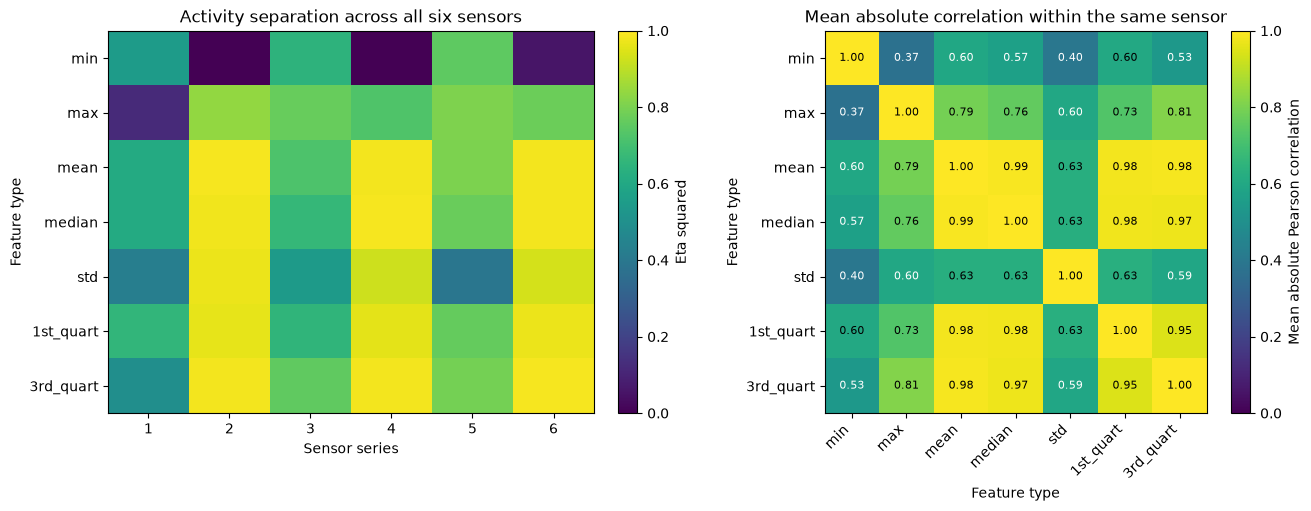

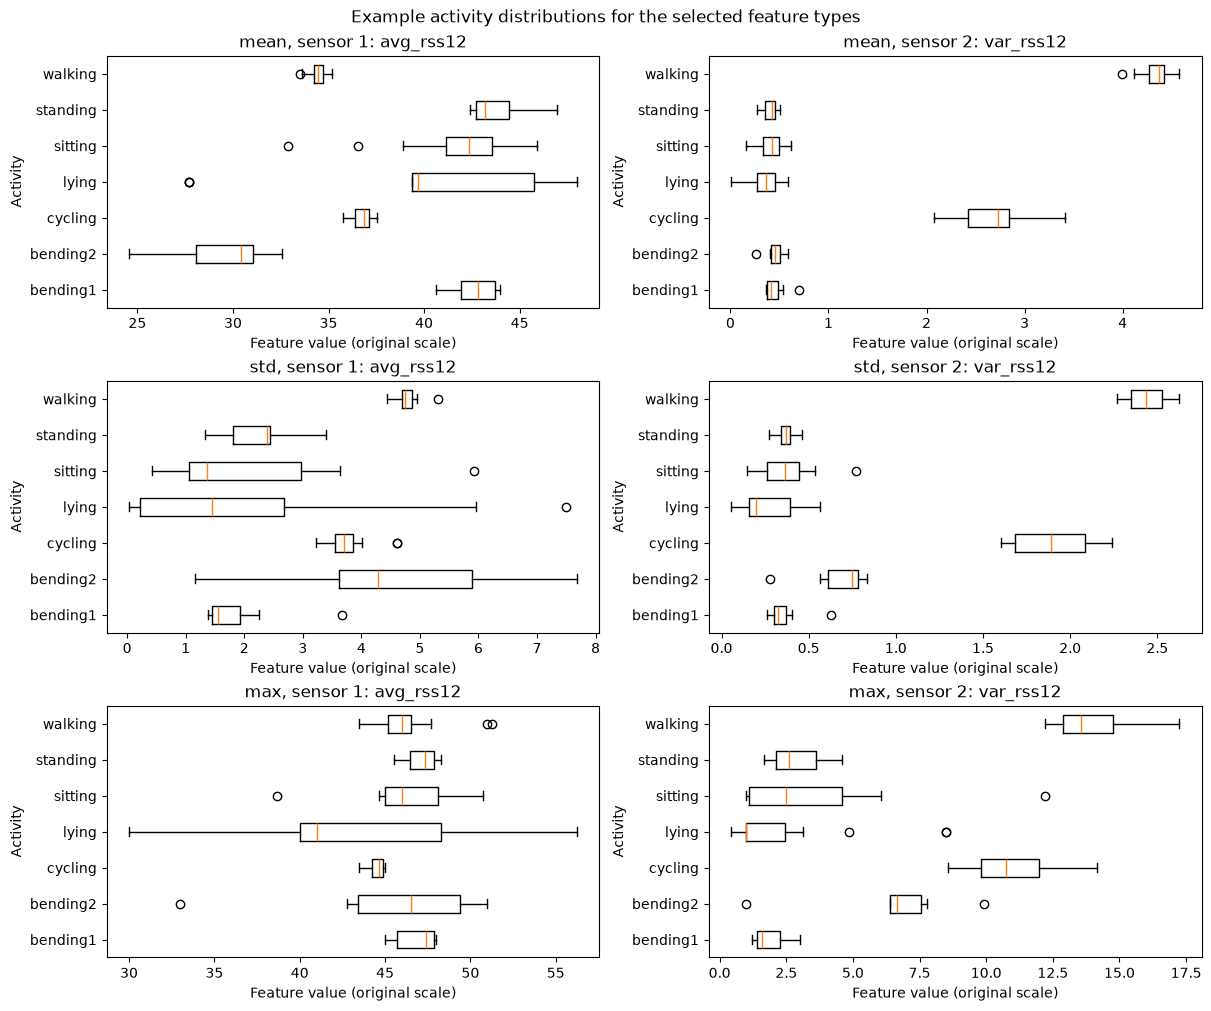

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5), layout="constrained")
image = axes[0].imshow(separation, vmin=0, vmax=1, cmap="viridis", aspect="auto")
axes[0].set_xticks(range(6), range(1, 7))
axes[0].set_yticks(range(7), feature_types)
axes[0].set_xlabel("Sensor series")
axes[0].set_ylabel("Feature type")
axes[0].set_title("Activity separation across all six sensors")
fig.colorbar(image, ax=axes[0], label="Eta squared")
image = axes[1].imshow(mean_abs_correlation, vmin=0, vmax=1, cmap="viridis")
axes[1].set_xticks(range(7), feature_types, rotation=45, ha="right")
axes[1].set_yticks(range(7), feature_types)
axes[1].set_xlabel("Feature type")
axes[1].set_ylabel("Feature type")
axes[1].set_title("Mean absolute correlation within the same sensor")
for row in range(7):
    for column in range(7):
        value = mean_abs_correlation.iloc[row, column]
        axes[1].text(column, row, f"{value:.2f}", ha="center", va="center",
                     color="black" if value > 0.6 else "white", fontsize=8)
fig.colorbar(image, ax=axes[1], label="Mean absolute Pearson correlation")
plt.show()

selected_types = ["mean", "std", "max"]
activity_order = sorted(activities.unique())
fig, axes = plt.subplots(3, 2, figsize=(12, 10), layout="constrained")
for row, kind in enumerate(selected_types):
    for column, sensor in enumerate([1, 2]):
        ax = axes[row, column]
        values = [features.loc[activities == activity, f"{kind}{sensor}"]
                  for activity in activity_order]
        ax.boxplot(values, orientation="horizontal", tick_labels=activity_order)
        ax.set_title(f"{kind}, sensor {sensor}: {columns[sensor]}")
        ax.set_xlabel("Feature value (original scale)")
        ax.set_ylabel("Activity")
fig.suptitle("Example activity distributions for the selected feature types")
plt.show()


From the figures, the mean, standard deviation, and maximum seem to be the most useful as well as provide non redundant information.

- Mean has the highest average activity-separation score (0.848). Median and the quartiles also separate activities well, but their average absolute correlations with mean exceed 0.98, so I avoid selecting several of these similar summaries.
- Standard deviation has an average separation score of 0.699 and a lower average absolute correlation with mean (0.625), contributing information about fluctuations within a recording.
- Maximum has an average separation score of 0.672 and correlations of 0.791 with mean and 0.600 with standard deviation. It provides a peak summary with less redundancy than the median or quartiles. Minimum is less correlated with mean, but its average separation score is only 0.334; two of its sensor columns are constant.


## 2. ISLR 3.7.4

### (a) Linear Train

The cubic model will have training RSS less than or equal to the linear model. It can reproduce the linear fit by setting its extra coefficients to zero, and its added flexibility may fit some training noise.

### (b) Linear Test

Given that the true relationship is linear, the cubic model may perform worse than the linear model due to overfitting. Hence, the RSS of the linear one would be expected to be lower.

### (c) Not Linear Train

Since we know that the true relationship is some non-linear function, the cubic model should perform better since it has the base terms of linear regression, and additional non-linear terms that may allow for better capability of modeling. Hence, the training RSS for the cubic function should be lower or at least equal to the linear one.

### (d) Not Linear Testing

It is not possible to give a conclusive answer since we don't know how the test data is varying. The cubic model may capture the nonlinear relationship better, but the linear model may perform better if the relationship is close to linear or the cubic model overfits.

## 3. ISLR 3.7.3 - Extra Practice 

## 3. ISLR 3.7.5 - Extra Practice 

## References

- [tsfresh: Overview on extracted features](https://tsfresh.readthedocs.io/en/latest/text/list_of_features.html): definitions and examples of time-series features for Part 1(c)(i).

- pandas documentation: [Series.std](https://pandas.pydata.org/docs/reference/api/pandas.Series.std.html) and [Series.quantile](https://pandas.pydata.org/docs/reference/api/pandas.Series.quantile.html), for sample standard deviations and linear-interpolated quartiles.

- [pandas DataFrame.sample](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.sample.html) and [NumPy percentile](https://numpy.org/doc/stable/reference/generated/numpy.percentile.html): row resampling with replacement and percentile bounds for Part 1(c)(iii).

- [pandas DataFrame.corr](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.corr.html): Pearson correlations used to compare redundancy between feature types in Part 1(c)(iv).

- [Matplotlib Axes.boxplot](https://matplotlib.org/stable/api/_as_gen/matplotlib.axes.Axes.boxplot.html): activity-wise boxplots for the selected feature types in Part 1(c)(iv).

- [statsmodels: ANOVA effect-size notes](https://www.statsmodels.org/stable/generated/statsmodels.stats.oneway._fstat2effectsize.html): eta-squared interpretation for the activity-separation scores in Part 1(c)(iv).

Generative AI assistance: Used Codex to help with assignment. Some of the prompts I used are listed below-

- "I'm running into some issues when attempting to load the data from @AReM. What is the correct way to load the data?"
- "What are time domain features? Which ones are usually used in time series classification? Give me some references to go through for better understanding"
- "How do I extract the following features in python: minimum, maximum, mean, median, standard deviation, first quartile, and third quartile. Explain with an example with proper syntax in python"
- "Will normalizing or standardizing the features make a difference? Explain in detail"
- "How do I estimate the standard deviation using Python's bootstrap?"
- "What makes a feature important in this example? How do I go about selecting the three most important time domain features?"


